# 3. Improved system

The improved pipeline: validated data, preparation learned on each training window only, nested walk-forward tuning, local ridge shrinkage and predictive variance — plus the regime-state MCLLR, whose kernel compares market regimes (trailing volatility and momentum) instead of factor returns.

In [1]:
import os, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from lrd import comparison as cmp

runs = {r.key: r for r in cmp.load_runs("app/data/default_run")[0]}
bench = runs[cmp.BENCHMARK_KEY]
improved = [r for k, r in runs.items() if k.startswith("improved:")]

## 3.1 Results (hyperparameters tuned inside every fold — no selection bias)

In [2]:
cols = ["key", "rmse", "oos_r2_%", "cw_p", "dm_p", "coverage_95", "interval_score_95", "cer_gain_%", "sharpe"]
cmp.summarize(improved, bench)[cols].sort_values("oos_r2_%", ascending=False).round(4)

,key,rmse,oos_r2_%,cw_p,dm_p,coverage_95,interval_score_95,cer_gain_%,sharpe
2,improved:mcllr_improved,0.0447,0.3618,0.0548,0.4421,0.9425,0.2345,1.2197,0.5359
1,improved:ridge,0.0447,0.2477,0.0883,0.6781,0.9444,0.2364,0.4485,0.4900
3,improved:mcllr_regime,0.0447,0.1520,0.1205,0.7875,0.9444,0.2324,1.2377,0.5373
0,improved:historical_mean,0.0448,0.0000,0.5000,1.0000,0.9405,0.2380,0.0000,0.4627


## 3.2 Original vs improved MCLLR on identical months

In [3]:
pair = [runs["standard:mcllr"], runs["improved:mcllr_improved"], runs["improved:mcllr_regime"]]
cmp.summarize(pair, bench)[["key", "oos_r2_%", "cw_p", "coverage_95", "cer_gain_%"]].round(4)

,key,oos_r2_%,cw_p,coverage_95,cer_gain_%
0,standard:mcllr,-6.5768,0.7091,0.3631,-0.6708
1,improved:mcllr_improved,0.3618,0.0548,0.9425,1.2197
2,improved:mcllr_regime,0.1520,0.1205,0.9444,1.2377


## 3.3 Tuning stability

Hyperparameters chosen in each fold by the inner walk-forward. Large jumps indicate a nearly flat validation error — a weak signal.

In [4]:
for key in ["improved:mcllr_improved", "improved:mcllr_regime"]:
    chosen = pd.DataFrame(list(runs[key].tuning["chosen"]))
    print(key)
    for col in chosen.columns:
        print("  ", col, chosen[col].value_counts().to_dict())

improved:mcllr_improved
   n_simulations {50: 42}
   subsample_size {160: 42}
   predictive_std {True: 42}
   bandwidth {3.0: 23, 1.0: 15, 2.0: 4}
   alpha {1.0: 22, 30.0: 16, 10.0: 3, 3.0: 1}
improved:mcllr_regime
   n_simulations {50: 42}
   subsample_size {160: 42}
   predictive_std {True: 42}
   state_window {12: 42}
   bandwidth {2.0: 19, 0.5: 16, 1.0: 7}
   alpha {1.0: 24, 30.0: 16, 10.0: 2}


## 3.4 Calibration

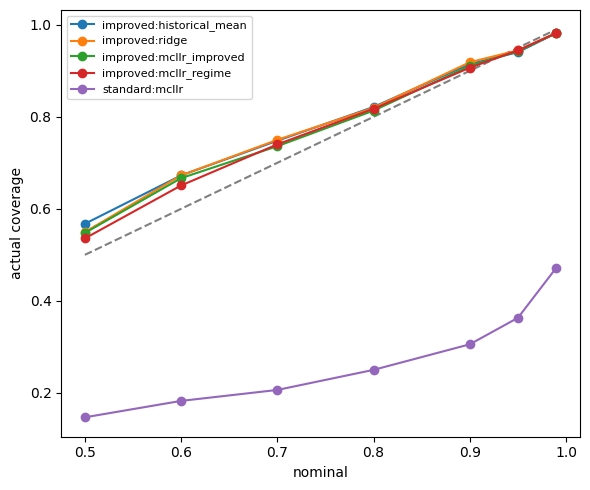

In [5]:
levels = [0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.99]
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([0.5, 0.99], [0.5, 0.99], "--", color="gray")
for run in improved + [runs["standard:mcllr"]]:
    ax.plot(levels, [cmp.coverage(run, lv) for lv in levels], marker="o", label=run.key)
ax.set_xlabel("nominal")
ax.set_ylabel("actual coverage")
ax.legend(fontsize=8)
plt.tight_layout()